# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement the search algorithm BFS for planning paths through mazes.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file.


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze.

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.**
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state.
* **Discrete** means that we have a **finite set of states.** The maze has a finite set
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible.

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [21]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [22]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`.

In [23]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))
print("Position(3,11):", mh.look(maze, (3, 11)))

Position(0,0): X
Position(8,1): G
Position(3,11): S


A helper function to visualize the maze is also available.

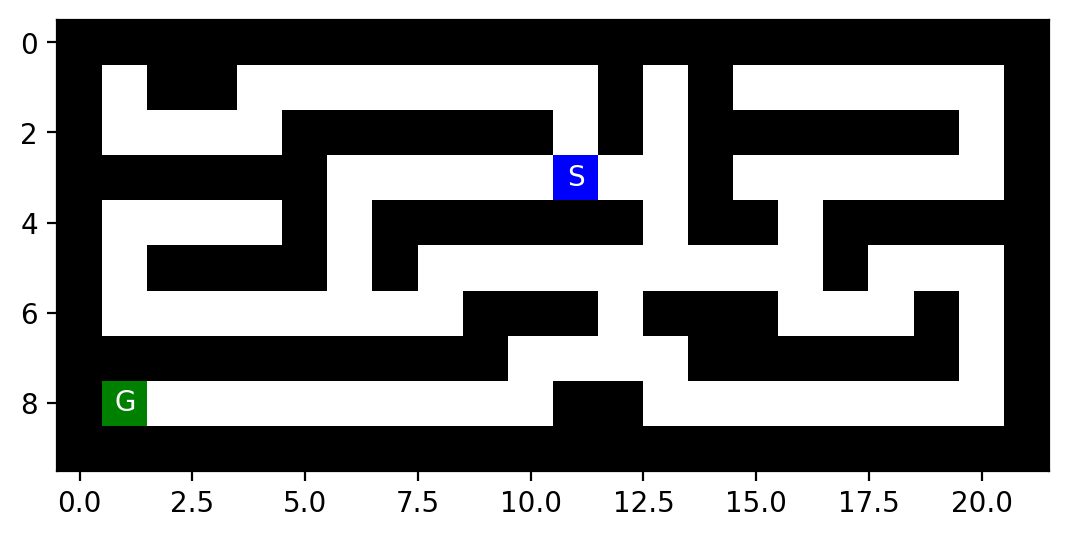

In [24]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [25]:
print("Start location:", mh.find_pos(maze))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [26]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step.

In [27]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0

        # check if plan is completed
        if self.progress >= len(self.plan):
            raise Exception("Completed Plan. No more planned actions")

        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [28]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['S', 'S', 'S', 'W', 'W', 'W', 'N', 'W', 'S', 'E']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [29]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: N
Following plan... step 2: E
Following plan... step 3: W
Following plan... step 4: N
Following plan... step 5: S
Following plan... step 6: E
Following plan... step 7: W
Following plan... step 8: N
Following plan... step 9: S
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python.
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [30]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"

    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]

        while not node.parent is None:
            node = node.parent
            path.append(node)

        path.reverse()

        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithm for solving different mazes:
    - Breadth-first search (BFS)

2. Run each of the above algorithms on the
    - [small maze](small_maze.txt),
    - [large maze](large_maze.txt),
    - [open maze](open_maze.txt), and
    - [empty maze](empty_maze.txt).

3. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [2 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate.

*Note:* You can switch the next block from code to Markdown and use formatting.

`<Your answer goes here>`
### 1. Định nghĩa Bài toán Tìm kiếm (Search Problem Formulation)

Bài toán giải mê cung bằng planning agent có thể được mô hình hóa dưới dạng bài toán tìm kiếm đơn tác nhân (single-agent), xác định (deterministic), quan sát hoàn toàn (fully observable) và hữu hạn (discrete) với các thành phần sau:

* **Trạng thái ban đầu (Initial State - $S_0$):**
  Được biểu diễn bằng một bộ 2 tọa độ `(hàng, cột)` tương ứng với vị trí xuất phát `'S'` trong ma trận mê cung (ví dụ: `(3, 11)` trong file `small_maze.txt`).

* **Hành động (Actions - $A(s)$):**
  Tập hợp các hướng di chuyển hợp lệ từ trạng thái hiện tại $s = (r, c)$.
  $$A(s) \subseteq \{\text{'N'}, \text{'S'}, \text{'E'}, \text{'W'}\}$$
  Một hành động được coi là hợp lệ nếu di chuyển theo hướng đó không va vào tường `'X'` và không đi ra ngoài phạm vi mê cung.

* **Mô hình chuyển trạng thái (Transition Model - $Result(s, a)$):**
  Hàm xác định ánh xạ một trạng thái $s = (r, c)$ và một hành động $a \in A(s)$ sang một trạng thái mới $s' = (r', c')$:
  * $\text{'N'} \rightarrow (r-1, c)$ (Bắc / Đi lên)
  * $\text{'S'} \rightarrow (r+1, c)$ (Nam / Đi xuống)
  * $\text{'E'} \rightarrow (r, c+1)$ (Đông / Sang phải)
  * $\text{'W'} \rightarrow (r, c-1)$ (Tây / Sang trái)

* **Trạng thái đích (Goal State - $G$):**
  Trạng thái $s = (r, c)$ mà ký tự tại ô đó trên mê cung bằng `'G'` (ví dụ: `(8, 1)` trong file `small_maze.txt`). Kiểm tra điều kiện đích: $\text{GoalTest}(s) \equiv (s == G)$.

* **Chi phí đường đi (Path Cost - $g(n)$):**
  Mỗi bước di chuyển có chi phí đồng nhất bằng $1$. Tổng chi phí đường đi $g(n)$ từ trạng thái ban đầu đến nút $n$ chính là tổng số bước đi/hành động đã thực hiện (tương ứng với độ sâu của nút $n$).

Give some estimates for the problem size:

* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

`<Your answer goes here>`

### 2. Ước lượng Kích thước Bài toán (Estimating Problem Size)

Kích thước của không gian tìm kiếm và độ phức tạp của mê cung được đặc trưng bởi các tham số sau:

* **$d$ (Độ sâu của lời giải tối ưu - Depth of the Optimal Solution):**
  * **Định nghĩa:** Chiều dài (số bước đi) chính xác của đường đi ngắn nhất từ trạng thái ban đầu $S$ đến trạng thái đích $G$.
  * **Cách xác định:** Đối với một mê cung cụ thể, $d$ được xác định bằng cách chạy một thuật toán tìm kiếm tối ưu như **Breadth-First Search (BFS)** hoặc **A\*** (với hàm heuristic hợp lệ). Chi phí/độ sâu của nút đích thu được từ BFS chính là $d$.

* **$m$ (Độ sâu tối đa của cây tìm kiếm / Không gian trạng thái - Maximum Depth):**
  * **Định nghĩa:** Độ dài đường đi lớn nhất có thể có mà không duyệt lặp lại trạng thái cũ (tương ứng với tổng số ô trống có thể đi tới trong mê cung).
  * **Cách xác định:**
    * Trong đồ thị lưới hữu hạn không lặp trạng thái, $m \le (\text{Số hàng} \times \text{Số cột}) - \text{Số ô tường ('X')}$.
    * Giá trị này có thể tìm được bằng cách chạy Depth-First Search (DFS) hoặc tìm đường đi đơn dài nhất trong đồ thị các trạng thái có thể đến được.

* **$b$ (Hệ số nhánh tối đa - Maximum Branching Factor):**
  * **Định nghĩa:** Số lượng hành động (trạng thái kế tiếp) hợp lệ tối đa có thể thực hiện từ bất kỳ trạng thái nào trong mê cung.
  * **Cách xác định:**
    * Vì tác nhân chỉ có thể di chuyển theo 4 hướng chính (Bắc, Nam, Đông, Tây) nên $b \le 4$.
    * Với một mê cung cụ thể, $b$ được xác định bằng cách kiểm tra tất cả các ô có thể đi vào (`' '`, `'S'`, `'G'`) và đếm số lượng ô xung quanh không phải là tường. Ví dụ, ở các khoảng không gian mở hoặc rỗng, các ô ngã tư cách xa tường sẽ có $b = 4$.

## Task 2: Breadth-First Search [5 Points]

Implement this simple search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important note** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.


In [34]:
# Your code goes here

from collections import deque

def plan_bfs(maze, start, goal):
    """
    Thuật toán Breadth-First Search (BFS) để tìm đường đi ngắn nhất trong mê cung.
    Trả về:
      - path_actions: Danh sách các hành động ('N', 'S', 'E', 'W') từ Start -> Goal.
      - nodes_expanded: Số lượng nút đã được mở rộng (expanded).
      - visited_maze: Bản đồ mê cung được ghi nhận các ô đã duyệt ('.' và 'P').
    """
    # Khởi tạo nút gốc
    start_node = Node(pos=start, parent=None, action=None, cost=0)

    # Kiểm tra ngay nếu Start là Goal
    if start == goal:
        return [], 0, maze.copy()

    # Hàng đợi Frontier (FIFO) cho BFS
    frontier = deque([start_node])
    # Tập hợp reached lưu các vị trí đã thêm vào frontier/mở rộng để tránh lặp
    reached = {tuple(start)}

    # Bảng dịch chuyển hướng và tọa độ
    directions = {
        'N': (-1, 0),
        'S': (1, 0),
        'E': (0, 1),
        'W': (0, -1)
    }

    nodes_expanded = 0
    goal_node = None

    while frontier:
        # Lấy nút ở đầu hàng đợi (FIFO)
        node = frontier.popleft()
        nodes_expanded += 1

        # Mở rộng các trạng thái kế tiếp
        for action, (dr, dc) in directions.items():
            neighbor_pos = (node.pos[0] + dr, node.pos[1] + dc)

            # Kiểm tra va chạm tường hoặc vượt ranh giới
            if 0 <= neighbor_pos[0] < maze.shape[0] and 0 <= neighbor_pos[1] < maze.shape[1]:
                tile = mh.look(maze, neighbor_pos)
                if tile != 'X' and neighbor_pos not in reached:
                    child_node = Node(pos=neighbor_pos, parent=node, action=action, cost=node.cost + 1)

                    # Kiểm tra đích (Goal Test) khi tạo nút
                    if neighbor_pos == goal:
                        goal_node = child_node
                        break

                    reached.add(neighbor_pos)
                    frontier.append(child_node)

        if goal_node:
            break

    if goal_node is None:
        print("Không tìm thấy đường đi!")
        return None, nodes_expanded, maze.copy()

    # Trích xuất đường đi từ nút gốc tới Goal
    path_nodes = goal_node.get_path_from_root()
    path_actions = [n.action for n in path_nodes if n.action is not None]
    path_positions = {n.pos for n in path_nodes}

    # Tạo bản đồ đánh dấu ô đã duyệt ('.') và ô thuộc đường đi chính ('P')
    visited_maze = maze.copy()
    for pos in reached:
        if pos != start and pos != goal:
            visited_maze[pos[0], pos[1]] = '.'

    for pos in path_positions:
        if pos != start and pos != goal:
            visited_maze[pos[0], pos[1]] = 'P'

    return path_actions, nodes_expanded, visited_maze

The result of the planning function is a sequence of actions. Fill out the following table:


| maze | path length | # of nodes expanded |
|-----------|-----------|------------------|
| small     |           |                  |
| large     |           |                  |
| open      |           |                  |
| empty     |           |                  |

Visualize the found path for each maze. You can look at the `show_maze()` function in [maze_helper.py](maze_helper.py) to see how you can visualize the path.

Maze         | Path Length  | # Nodes Expanded  
------------------------------------------------
small_maze   | 19           | 90                
large_maze   | 210          | 617               
open_maze    | 54           | 679               
empty_maze   | 14           | 92                


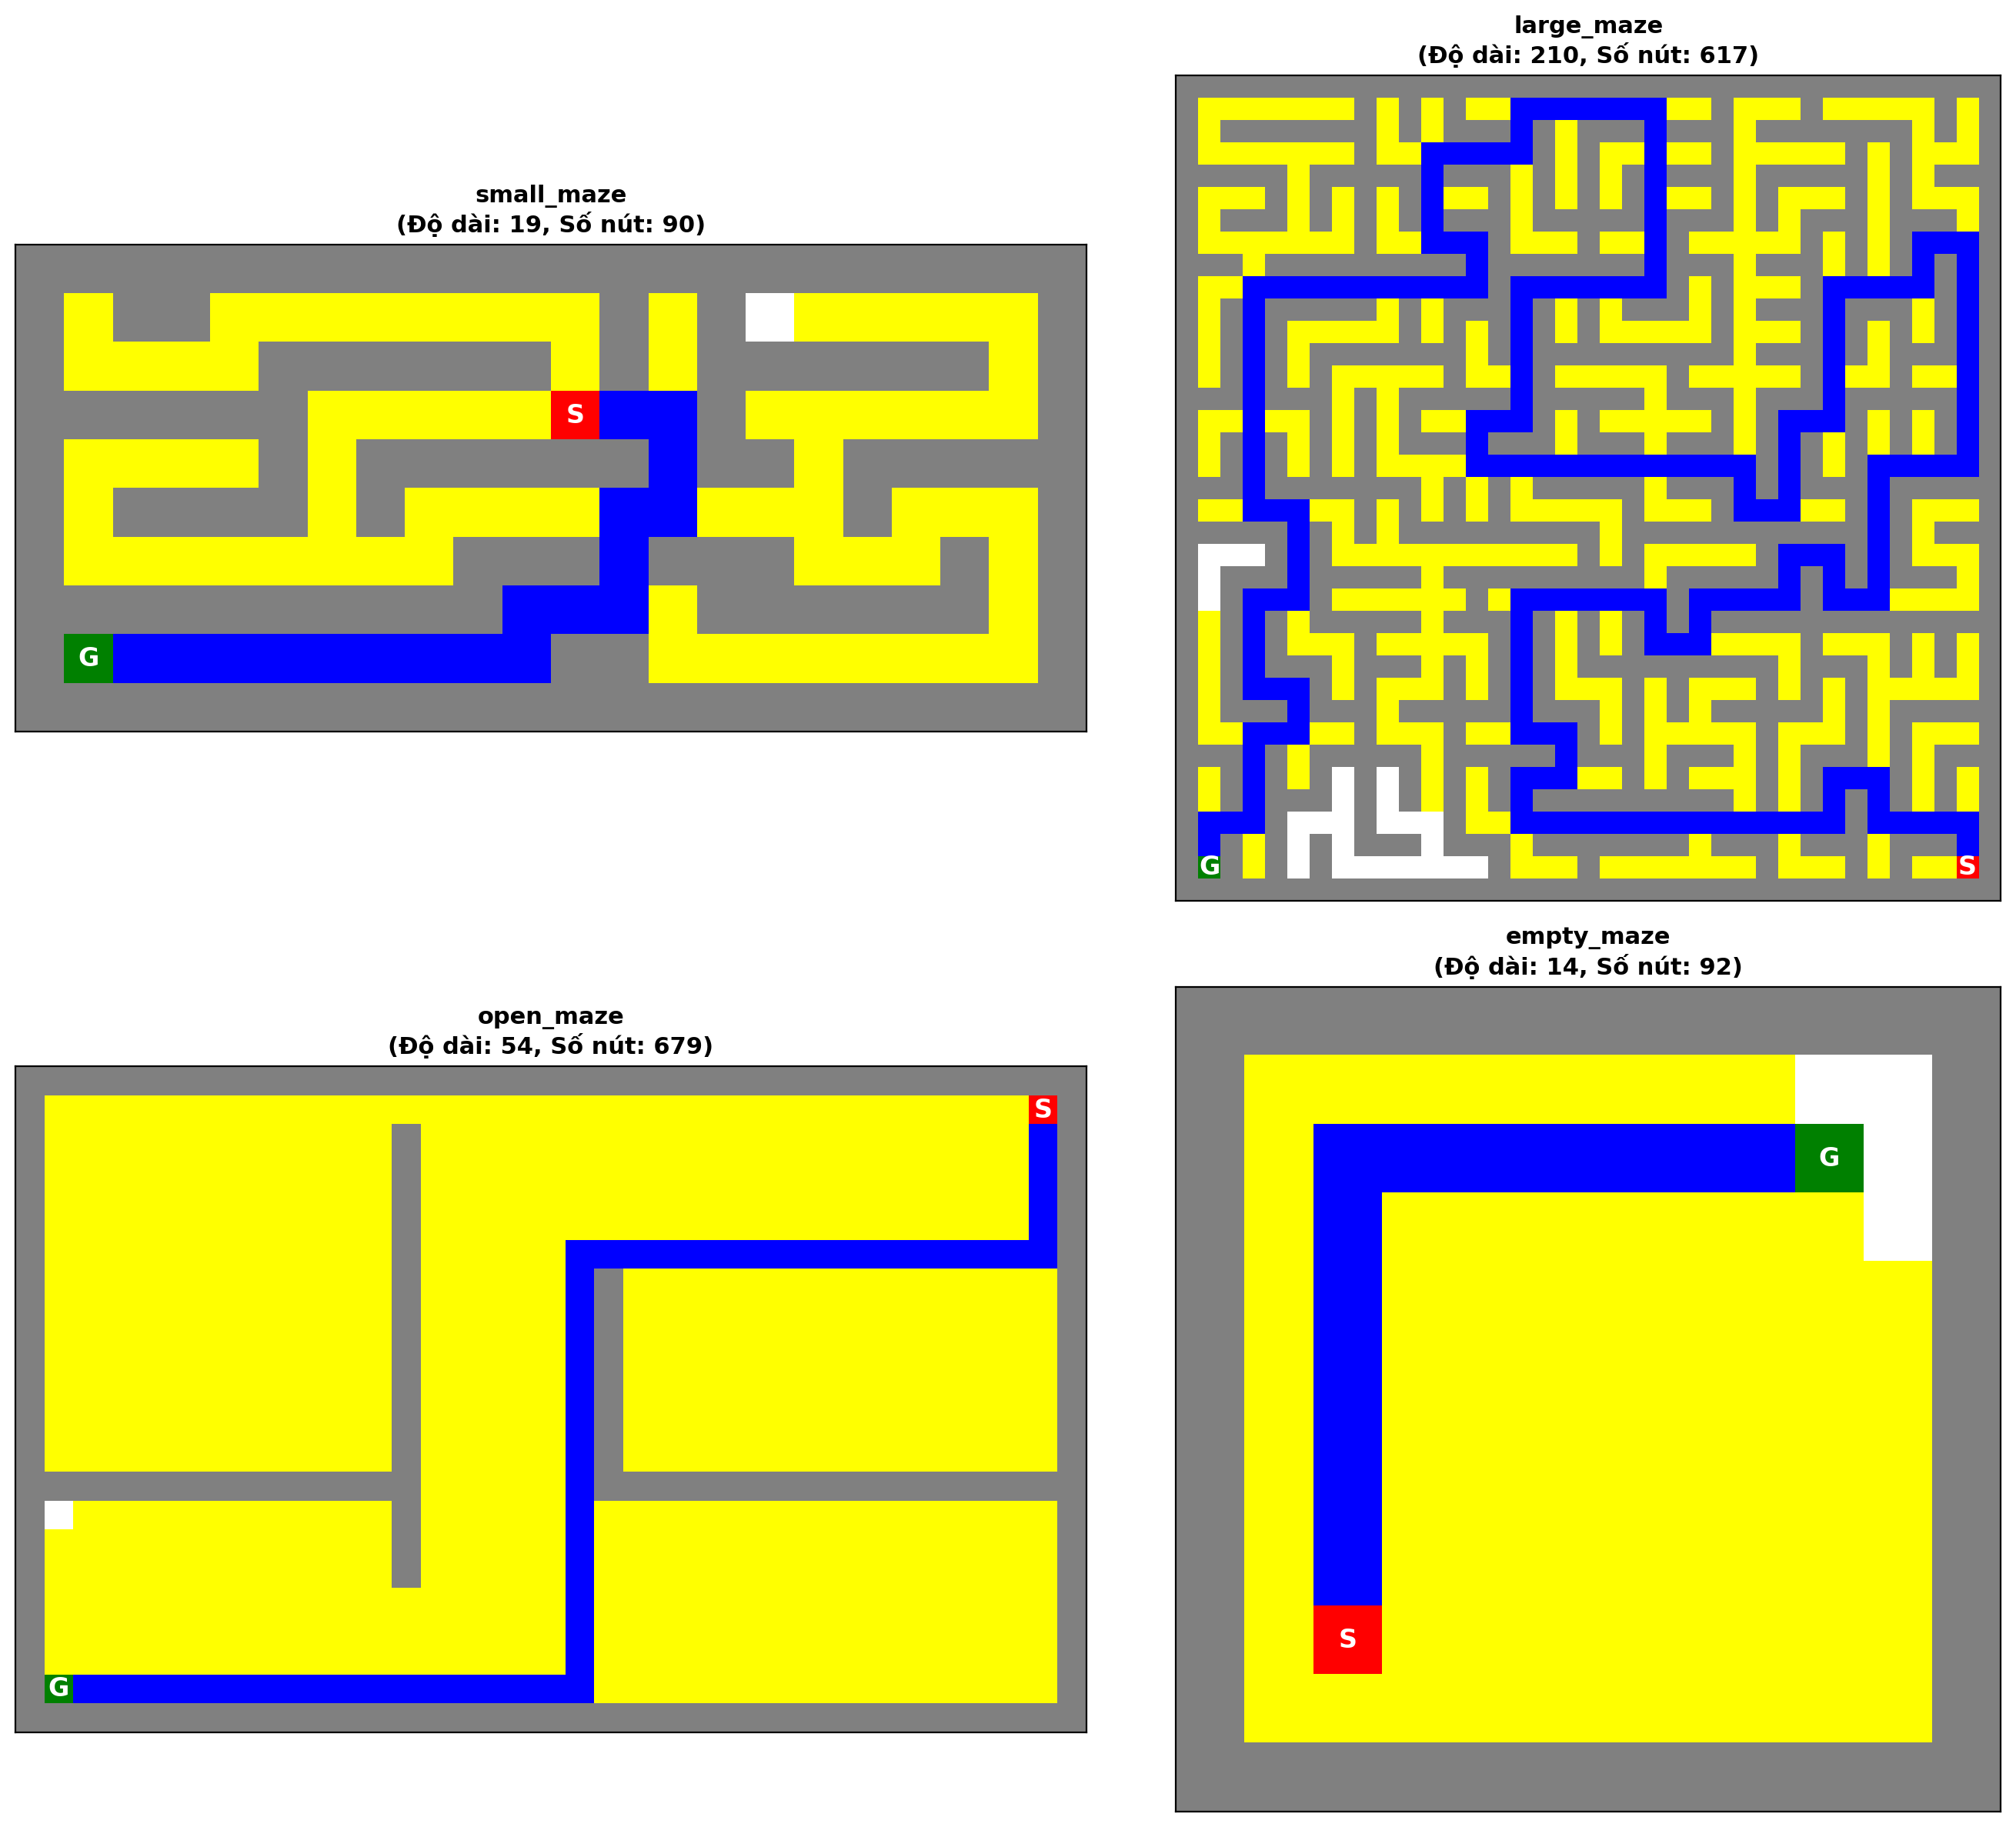

In [43]:
# Your code goes here

import matplotlib.pyplot as plt
from matplotlib import colors
import numpy as np

mazes_files = ["small_maze.txt", "large_maze.txt", "open_maze.txt", "empty_maze.txt"]
results = []

for file_name in mazes_files:
    # Đọc và parse mê cung
    with open(file_name, "r") as f:
        m_str = f.read()
    m_arr = mh.parse_maze(m_str)

    start_pos = mh.find_pos(m_arr, what="S")
    goal_pos = mh.find_pos(m_arr, what="G")

    # Chạy BFS
    actions, nodes_expanded, vis_maze = plan_bfs(m_arr, start_pos, goal_pos)
    path_length = len(actions) if actions is not None else 0

    results.append({
        "maze": file_name.replace(".txt", ""),
        "path_length": path_length,
        "nodes_expanded": nodes_expanded,
        "vis_maze": vis_maze
    })

# --- IN BẢNG KẾT QUẢ ---
print(f"{'Maze':<12} | {'Path Length':<12} | {'# Nodes Expanded':<18}")
print("-" * 48)
for res in results:
    print(f"{res['maze']:<12} | {res['path_length']:<12} | {res['nodes_expanded']:<18}")

# --- TRỰC QUAN HÓA (VISUALIZATION) ---

# Định nghĩa bảng màu giống hệt như trong maze_helper.py
# ' ' -> 0 (trắng), 'X' -> 1 (xám), 'S' -> 2 (đỏ), 'G' -> 3 (xanh lá)
# 'P' -> 4 (đường đi màu xanh lam), '.' -> 5 (màu vàng nhạt), 'F' -> 6
color_map_dict = {' ': 0, 'X': 1, 'S': 2, 'G': 3, 'P': 4, '.': 5, 'F': 6}
cmap = colors.ListedColormap(['white', 'gray', 'red', 'green', 'blue', 'yellow', 'orange'])
norm = colors.BoundaryNorm(list(range(8)), cmap.N)

# Khởi tạo khung hình chia làm 4 (2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for i, res in enumerate(results):
    # Lấy ma trận ký tự
    vis_maze = res['vis_maze']

    # Chuyển đổi ma trận ký tự sang ma trận số để vẽ bằng imshow
    numeric_maze = np.zeros(vis_maze.shape, dtype=int)
    for char, val in color_map_dict.items():
        numeric_maze[vis_maze == char] = val

    # Vẽ lên subplot hiện tại
    ax = axes[i]
    ax.imshow(numeric_maze, cmap=cmap, norm=norm)

    # Tắt các trục tọa độ cho đẹp
    ax.set_xticks([])
    ax.set_yticks([])

    # Thêm text ký tự 'S' và 'G' vào hình tương tự như thư viện
    rows, cols = vis_maze.shape
    for r in range(rows):
        for c in range(cols):
            if vis_maze[r, c] == 'S':
                ax.text(c, r, 'S', color='white', ha='center', va='center', fontweight='bold', fontsize=12)
            elif vis_maze[r, c] == 'G':
                ax.text(c, r, 'G', color='white', ha='center', va='center', fontweight='bold', fontsize=12)

    # Đặt tiêu đề cho từng ô
    ax.set_title(f"{res['maze']}\n(Độ dài: {res['path_length']}, Số nút: {res['nodes_expanded']})", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Task 3: Discussion [3 Points]

Is your implementation complete and optimal? Explain why. What is the time and space complexity of each of **your** implementation?

### Thảo luận: Tính Đầy đủ, Tính Tối ưu và Độ phức tạp của BFS

#### 1. Tính đầy đủ (Completeness)
* **Cài đặt này có Đầy đủ không?** **Có (Yes).**
* **Giải thích:** Thuật toán Breadth-First Search (BFS) đảm bảo tìm thấy lời giải nếu lời giải đó tồn tại, miễn là hệ số nhánh (branching factor $b$) hữu hạn. Trong bài toán mê cung này, hệ số nhánh tối đa $b \le 4$ (hữu hạn) và không gian trạng thái cũng hữu hạn, do đó thuật toán chắc chắn sẽ tìm ra đường đi từ $S$ đến $G$ nếu có đường đi kết nối giữa hai điểm này.

#### 2. Tính tối ưu (Optimality)
* **Cài đặt này có Tối ưu không?** **Có (Yes).**
* **Giải thích:** BFS tối ưu khi chi phí bước đi là đồng nhất (hằng số) trên mọi cạnh (ở đây mỗi bước di chuyển có chi phí bằng $1$). BFS duyệt theo từng tầng độ sâu tăng dần từ gốc. Do đó, nút đích đầu tiên được tìm thấy và đưa vào danh sách đích chắc chắn sẽ là nút có độ sâu ngắn nhất (tương ứng với số bước đi ít nhất).

#### 3. Độ phức tạp (Complexity)
* **Độ phức tạp Thời gian (Time Complexity):** $O(b^d)$
  * Trong trường hợp xấu nhất, thuật toán phải duyệt qua toàn bộ các nút ở độ sâu $d$ (độ sâu của lời giải tối ưu). Với $b$ là hệ số nhánh, tổng số nút được tạo ra và kiểm tra tỷ lệ thuận với $b^d$.
* **Độ phức tạp Không gian (Space Complexity):** $O(b^d)$
  * BFS cần lưu trữ toàn bộ các nút đã duyệt trong cấu trúc dữ liệu `reached` (tập trạng thái đã mở rộng/thêm vào frontier) và lưu các nút đang chờ duyệt trong hàng đợi `frontier` (FIFO). Do đó, lượng bộ nhớ yêu cầu tăng theo hàm mũ của độ sâu đường đi $d$.

How would the planning improve if you use informed search with A* search and the Euclidean distance to the goal as the heuristic? What would the algorithm do differently?

### Thảo luận: Cải tiến với Tìm kiếm Thông tin (Informed Search) - Thuật toán A*

Nếu chúng ta sử dụng thuật toán **A\*** kết hợp với hàm Heuristic là **khoảng cách Euclidean (Euclidean Distance)** tới đích, quá trình tìm kiếm sẽ được cải tiến vượt trội:

#### 1. Sự cải tiến trong quá trình tìm kiếm
* **Định hướng tìm kiếm:** Thay vì duyệt đều ra mọi hướng theo kiểu "vết dầu loang" (vòng tròn đồng tâm) như BFS, thuật toán A\* sẽ sử dụng hàm đánh giá $f(n) = g(n) + h(n)$:
  * $g(n)$: Chi phí thực tế từ Start đến nút hiện tại.
  * $h(n)$: Ước lượng chi phí từ nút hiện tại đến Goal (khoảng cách Euclidean: $\sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}$).
* **Giảm số lượng nút mở rộng (Expanded Nodes):** Các nút nằm trên hướng đi thẳng hoặc gần về phía mục tiêu sẽ có giá trị $f(n)$ nhỏ hơn và được ưu tiên duyệt trước. Thuật toán sẽ hạn chế tối đa việc đi chệch hướng hoặc mở rộng các nhánh đi ngược lại với Goal. Nhờ đó, số lượng nút cần mở rộng sẽ giảm đi rất nhiều so với BFS, đặc biệt là trong các mê cung lớn hoặc không gian mở (`open_maze`).

#### 2. Sự khác biệt trong hành vi của thuật toán
* **Cấu trúc dữ liệu:** Thay vì sử dụng hàng đợi thông thường (FIFO Queue) như BFS, A\* sử dụng một **Hàng đợi ưu tiên (Priority Queue / Min-Heap)** sắp xếp theo giá trị $f(n)$ tăng dần.
* **Hành vi duyệt:** Khi gặp các khu vực không gian rộng lớn không có tường chắn (như `open_maze` hoặc `empty_maze`), A\* sẽ vẽ một đường gần như là đường thẳng hướng trực diện từ $S$ tới $G$. Trong khi đó, BFS sẽ phải quét qua gần như toàn bộ các ô trống xung quanh $S$ trước khi chạm tới $G$.

Your BFS implementation works fine to solve small mazes. Why would it not work for larger problems with millions of states and 100s of actions? What algorithm could be used then?

### Thảo luận: Giới hạn của BFS và Giải pháp cho Bài toán Siêu lớn

#### 1. Tại sao BFS không hoạt động hiệu quả trên bài toán siêu lớn?
Khi đối mặt với các bài toán có hàng triệu trạng thái và hàng trăm hành động khả thi tại mỗi bước, BFS nhanh chóng thất bại vì hai lý do cốt lõi:
* **Nghẽn bộ nhớ (Space Complexity Explosion):** Đây là điểm yếu chí mạng của BFS. Với $O(b^d)$, lượng bộ nhớ cần thiết để duy trì hàng đợi `frontier` và tập hợp `reached` sẽ tăng theo cấp số nhân. Ví dụ, nếu $b = 10$ và độ sâu lời giải $d = 10$, hệ thống cần lưu trữ khoảng $10^{10}$ nút, điều này vượt quá dung lượng RAM của bất kỳ máy tính thông thường nào.
* **Thời gian thực thi quá lớn:** Việc duyệt tuần tự hàng triệu trạng thái mà không có bất kỳ định hướng thông minh nào sẽ tiêu tốn quá nhiều chu kỳ CPU.

#### 2. Các thuật toán thay thế hiệu quả hơn
Để giải quyết các không gian trạng thái khổng lồ, người ta sử dụng các thuật toán tối ưu hơn về mặt bộ nhớ hoặc có định hướng thông minh:

* **Iterative Deepening Search (IDS):**
  * Kết hợp ưu điểm của DFS (tiết kiệm bộ nhớ với độ phức tạp không gian chỉ là $O(b \cdot d)$) và BFS (đảm bảo tính tối ưu và đầy đủ). IDS thực hiện DFS lặp lại với giới hạn độ sâu tăng dần.

* **Memory-bounded A* (như IDA* - Iterative Deepening A* hoặc SMA*):**
  * Sử dụng kỹ thuật lặp độ sâu kết hợp với hàm heuristic để giới hạn bộ nhớ tối đa sử dụng, chỉ giữ lại các nút hứa hẹn nhất trên cây tìm kiếm.

* **Tránh lưu trữ toàn bộ trạng thái (Bidirectional Search):**
  * Tìm kiếm đồng thời từ hai phía (từ Start đi tới và từ Goal đi lui), giúp giảm độ phức tạp không gian và thời gian từ $O(b^d)$ xuống còn $O(b^{d/2})$.